!# Micromagnetics quickstart
A Néel skyrmion in a Co/Pt nanodisk, its relaxation, and the response to a field pulse.

Mesh 64x64x1 cells of 1x1x0.6 nm^3 (64 x 64 x 0.6 nm^3), pbc=(False, False, False)
  magnetic cells 3228 / 4096, regions: ['CoPt']
  Ms      5.8e+05 .. 5.8e+05
  A       1.5e-11 .. 1.5e-11
  D_int   0.003 .. 0.003
  Ku1     6e+05 .. 6e+05
  alpha   0.3 .. 0.3
  exchange length l_ex = 8.42 nm  (cell 1 nm)
  wall width pi sqrt(A/K) = 15.71 nm, K_eff = Ku1 - mu0 Ms^2/2 = 6e+05 J/m^3
  |D| / D_c = 0.785  (D_c = 4 sqrt(A K_eff)/pi = 3.820 mJ/m^2; > 1 -> spin spirals)


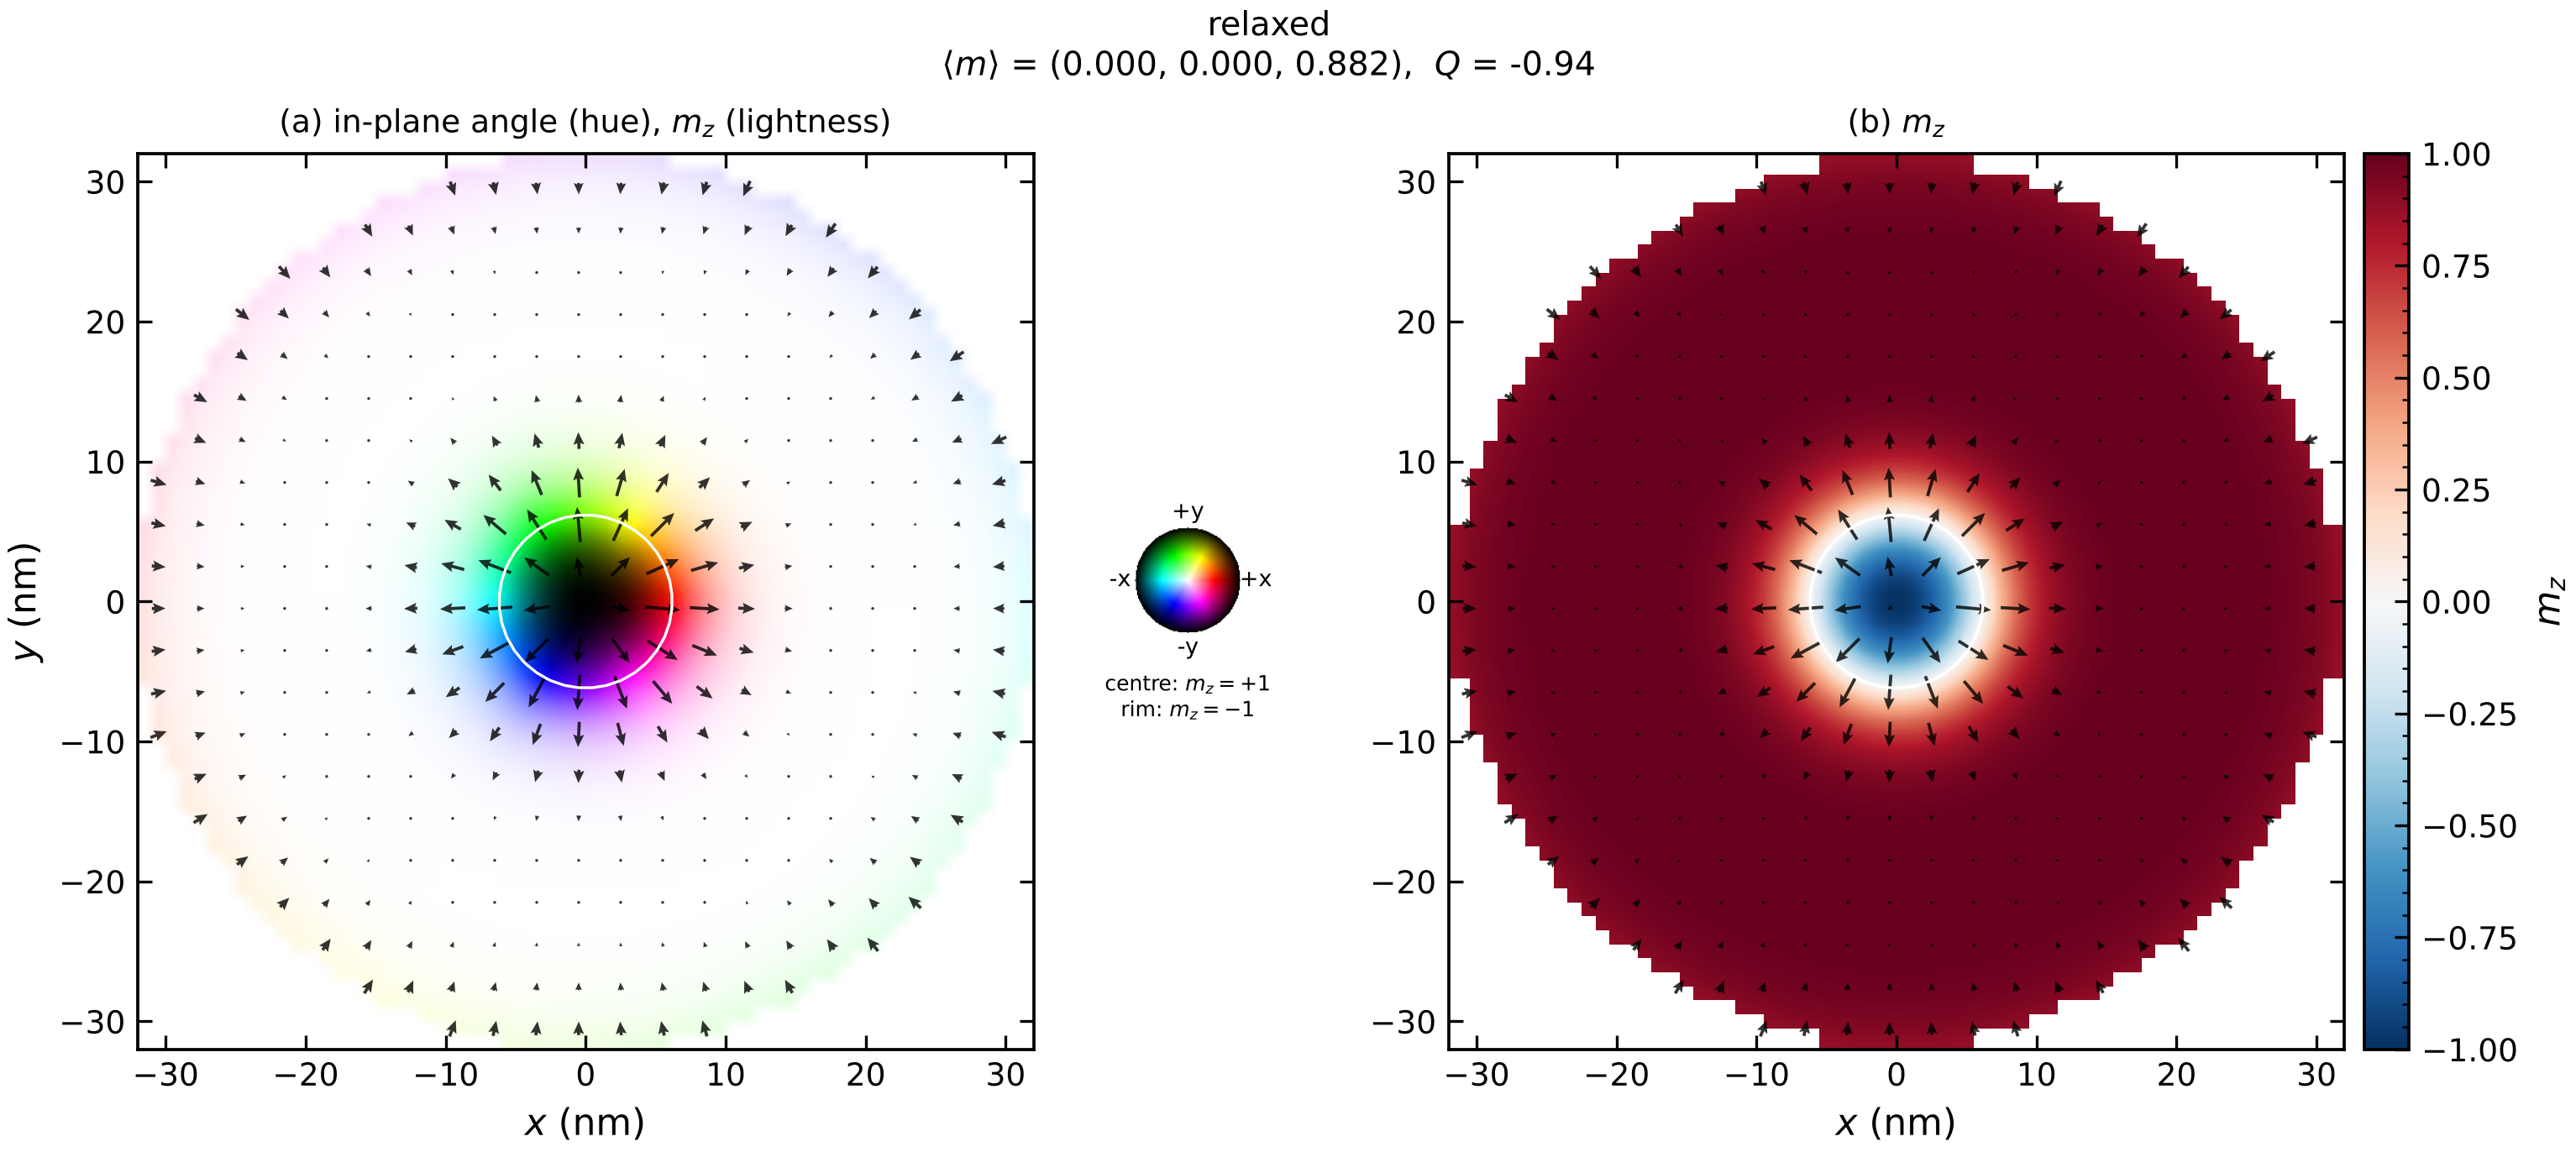

In [1]:
import numpy as np
from magex.micromag import Mesh, Micromagnet, geometry_mask, material, relax, RK45
from magex.micromag.plot import plot_state, plot_table
mesh = Mesh((64, 64, 1), (1.0e-9, 1.0e-9, 0.6e-9))
mm = Micromagnet(mesh, demag=False)          # ultrathin film: effective anisotropy instead of demag
mm.add_region(geometry_mask(mesh, "disk", diameter_nm=64), "CoPt", **material("Co/Pt", Ku1=6e5))
print(mm.summary())
m = relax(mm, mm.init("skyrmion", radius_nm=8))
plot_state(mm, m, "skyrmion.png", title="relaxed")
from IPython.display import Image; Image("skyrmion.png", width=620)

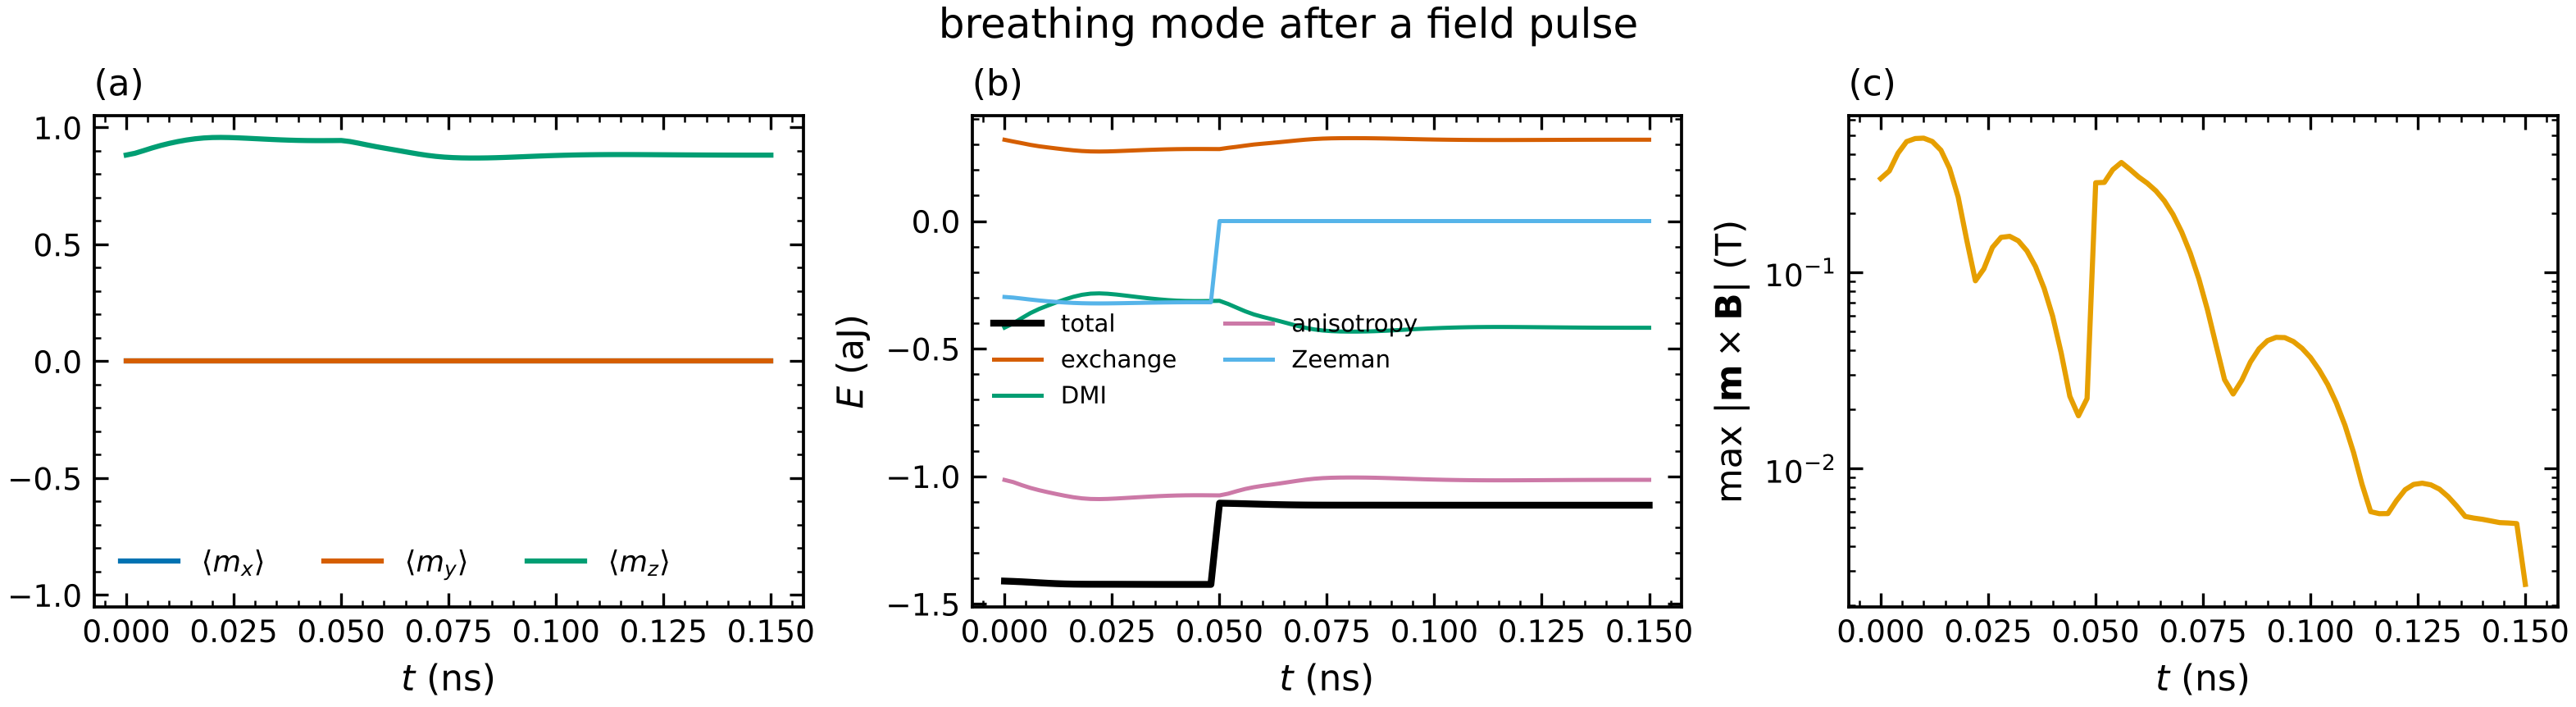

In [2]:
mm.B_func = lambda t: np.array([0, 0, 0.3]) * (t < 50e-12)     # 50 ps field pulse
m, table = RK45(mm).run(m, 0.15e-9, record_every=2e-12)
plot_table(table, "pulse.png", "breathing mode after a field pulse")
Image("pulse.png", width=780)